# Mandatory assignment 3

**GitHub repository:** *Insert the URL to your repository here.*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [221]:
import pandas as pd

In [222]:
# Loading in the dataframe

file = 'SCF_10pct.csv'
df = pd.read_csv(file)
df

,id,year,age,educ,stocks,equity
0,0,1989,35,2.0,0.0,0.0
1,1,1989,33,2.0,0.0,0.0
2,2,1989,62,1.0,0.0,0.0
3,3,1989,23,2.0,0.0,0.0
4,4,1989,70,1.0,0.0,0.0
...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0
5804,5804,2022,33,3.0,0.0,0.0
5805,5805,2022,81,2.0,100000.0,100000.0
5806,5806,2022,58,3.0,40000.0,1212000.0


In [223]:
#Number of non-missing values for each column
df.count()

id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64

In [224]:
# Dropping all observations with missing values

## Need to take away before next cell
#df = df.dropna(subset=['educ', 'stocks', 'equity'])
#df

In [225]:
# Checking that all NAN-missing values are gone
df.isna().sum()

id         0
year       0
age        0
educ      16
stocks    18
equity    16
dtype: int64

In [226]:
# Looping over amount of observations dropped and what remains for each variable
for var in ['id', 'year', 'age', 'educ', 'stocks', 'equity']:
    length = len(df)
    df = df.dropna(subset=[var])
    new_length = len(df)
    obs_dropped = length - new_length
    print(f'In {var}: {obs_dropped} observations was dropped and {new_length} remain')

In id: 0 observations was dropped and 5808 remain
In year: 0 observations was dropped and 5808 remain
In age: 0 observations was dropped and 5808 remain
In educ: 16 observations was dropped and 5792 remain
In stocks: 18 observations was dropped and 5774 remain
In equity: 16 observations was dropped and 5758 remain


In [227]:
df = df.dropna(subset=['educ', 'stocks', 'equity'])
df

,id,year,age,educ,stocks,equity
0,0,1989,35,2.0,0.0,0.0
1,1,1989,33,2.0,0.0,0.0
2,2,1989,62,1.0,0.0,0.0
3,3,1989,23,2.0,0.0,0.0
4,4,1989,70,1.0,0.0,0.0
...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0
5804,5804,2022,33,3.0,0.0,0.0
5805,5805,2022,81,2.0,100000.0,100000.0
5806,5806,2022,58,3.0,40000.0,1212000.0


In [228]:
# creating a boolean mask to filtrate for ages between or equal to 25 & 89

length2 = len(df)
mask = (df['age'] >= 25) & (df['age'] <= 89)
df = df[mask]
obs_dropped2 = length2 - len(df)
print(f'Observations dropped: {obs_dropped2}, Remaining: {len(df)}')


Observations dropped: 326, Remaining: 5432


In [229]:
# New column: direct participation

df['direct'] = (df['stocks'] > 0).astype(int)
df['direct']

0       0
1       0
2       0
4       0
5       0
       ..
5802    0
5804    0
5805    1
5806    1
5807    0
Name: direct, Length: 5432, dtype: int64

In [230]:
#New column: indirect participation
df['overall'] = (df['equity'] > 0).astype(int)
df['overall']

0       0
1       0
2       0
4       0
5       0
       ..
5802    0
5804    0
5805    1
5806    1
5807    1
Name: overall, Length: 5432, dtype: int64

In [231]:
# Comparing the result next to each other
df[['stocks', 'equity', 'direct', 'overall']].loc[3000:3020]

,stocks,equity,direct,overall
3000,0.0,14310.0,0,1
3001,0.0,0.0,0,0
3002,0.0,0.0,0,0
3003,21465.0,26616.6,1,1
3004,0.0,7870.5,0,1
3005,0.0,7155.0,0,1
3006,0.0,0.0,0,0
3008,0.0,42214.5,0,1
3009,0.0,0.0,0,0
3011,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [232]:
# defining the participation rate function
def participation_rate(indicator):
    count1 = 0
    for i in indicator:
        if i == 1:
            count1 += 1
    return (count1/len(indicator)) * 100

In [233]:
# Applying functios to direct and overall and reporting the rates
print(f'Direct participation rate: {participation_rate(df['direct']):.2f}%')
print(f'Overall participation rate: {participation_rate(df['overall']):.2f}%')

Direct participation rate: 16.96%
Overall participation rate: 49.41%


In [234]:
# finding the direct and overall participation rate using panda's built-in mean() method
print(f'Direct participation rate: {df['direct'].mean() * 100:.2f}%')
print(f'Overall participation rate: {df['overall'].mean() * 100:.2f}%')

Direct participation rate: 16.96%
Overall participation rate: 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [235]:
# crating two empty lists to store the results
direct_rates = []
overall_rates = []

# Looping over education and calculating direct and overall participation rate, and displaying the result
for edu in [1, 2, 3, 4]:
    mask = df['educ'] == edu
    edu_group = df[mask]
    direct = (participation_rate(edu_group['direct']))
    overall = (participation_rate(edu_group['overall']))
    direct_rates.append(direct)
    overall_rates.append(overall)
    print(f'Education level {edu}: The direct participaion rate is {direct:.1f}% and the overall participation rate is {overall:.1f}% =')



Education level 1: The direct participaion rate is 4.4% and the overall participation rate is 17.3% =
Education level 2: The direct participaion rate is 11.4% and the overall participation rate is 39.9% =
Education level 3: The direct participaion rate is 13.5% and the overall participation rate is 48.3% =
Education level 4: The direct participaion rate is 30.5% and the overall participation rate is 73.5% =


In [236]:
import matplotlib.pyplot as plt

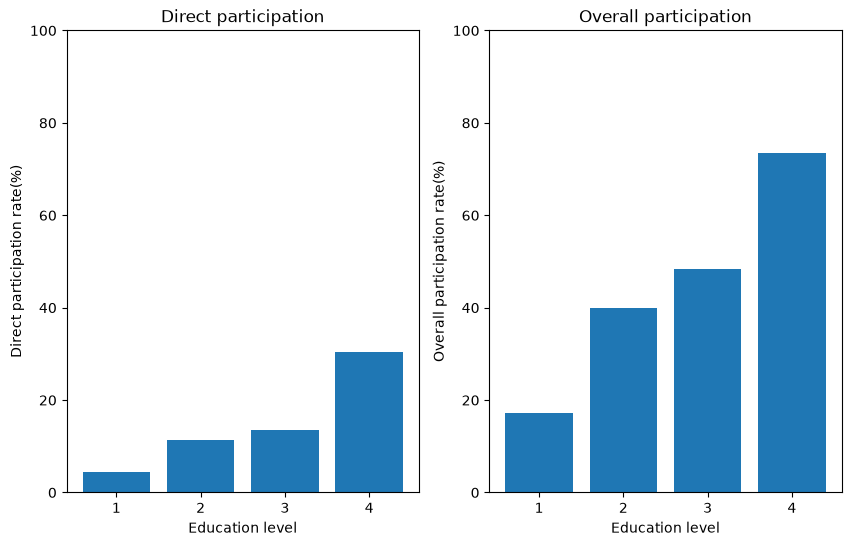

In [237]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].bar([1, 2, 3, 4], direct_rates)
axes[0].set_title('Direct participation')
axes[0].set_xlabel('Education level')
axes[0].set_ylabel('Direct participation rate(%)')
axes[0].set_ylim(0, 100)


axes[1].bar([1, 2, 3, 4], overall_rates)
axes[1].set_title('Overall participation')
axes[1].set_xlabel('Education level')
axes[1].set_ylabel('Overall participation rate(%)')
axes[1].set_ylim(0, 100)

plt.show()


Here we see that the participation rates, both direct and overall, and the level of education follow the same upwards pattern. The more education in a household the more they participate, both directly and overall. So we can say that higher education is assosiated with higher participation.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [ ]:
# creating empty lists to store the information from the loop
years = []
direct_rates_t = []
overall_rates_t = []

# looping over years and  filling up the list empty lists witht he output
for yr in sorted(df['year'].unique()):
    mask = df['year'] == yr
    yr_group = df[mask]
    direct = participation_rate(yr_group['direct'])
    overall = participation_rate(yr_group['overall'])
    years.append(yr)
    direct_rates_t.append(direct)
    overall_rates_t.append(overall)
    print(f'In {yr}: direct participation was {direct:.1f}% and overall participation was {overall:.1f}%.')



In 1989: direct participation was 15.6% and overall participation was 31.6%.
In 1992: direct participation was 18.3% and overall participation was 40.1%.
In 1995: direct participation was 15.7% and overall participation was 45.9%.
In 1998: direct participation was 19.9% and overall participation was 51.2%.
In 2001: direct participation was 21.8% and overall participation was 57.0%.
In 2004: direct participation was 18.9% and overall participation was 54.7%.
In 2007: direct participation was 17.3% and overall participation was 56.5%.
In 2010: direct participation was 17.4% and overall participation was 50.3%.
In 2013: direct participation was 14.8% and overall participation was 49.9%.
In 2016: direct participation was 12.3% and overall participation was 52.0%.
In 2019: direct participation was 12.4% and overall participation was 49.8%.
In 2022: direct participation was 19.2% and overall participation was 54.3%.


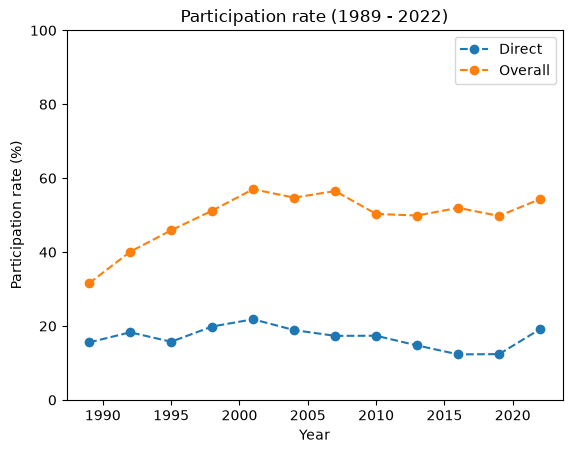

In [264]:
# Making a line plot from the data
plt.plot(years, direct_rates_t, marker='o', label='Direct', ls='--')
plt.plot(years, overall_rates_t, marker='o', label='Overall', ls='--')
plt.title('Participation rate (1989 - 2022)')
plt.xlabel('Year')
plt.ylabel('Participation rate (%)')
plt.legend()
plt.ylim(0, 100)
plt.show()

In [265]:
# Changes in participation rate from 1989 to 2022 in percentage points (direct and overall)
p_point_direct = direct_rates_t[-1] - direct_rates_t[0]
p_point_overall = overall_rates_t[-1] - overall_rates_t[0]

print(f'The difference from 1989 and 2022: Direct participation = {p_point_direct:.2f} percentage points & Overall participation = {p_point_overall:.2f} percentage points')


The difference from 1989 and 2022: Direct participation = 3.58 percentage points & Overall participation = 22.76 percentage points


The graph shows that the overall participation rose significantly with the diffference being 22.76 percentage points. The direct participation only rose by 3.58 percentage points. We therefore see that people have gotten more exposed to the stock market trough indirect means rather than stocks.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used AI with helping me understand the task thourougly before I began writing. AI also helped me everytime I got stuck or with technical problems in VS Code. I asked it to not just give me the answer, but try to explain the logic and which commands to use and put together. I also used it to explain some commands that I did not understand properly more thorughly.